# 1. Mengambil Dataset

Total gambar ditemukan: 6594
Sample: /kaggle/input/datasets/fanconic/skin-cancer-malignant-vs-benign/test/benign/946.jpg


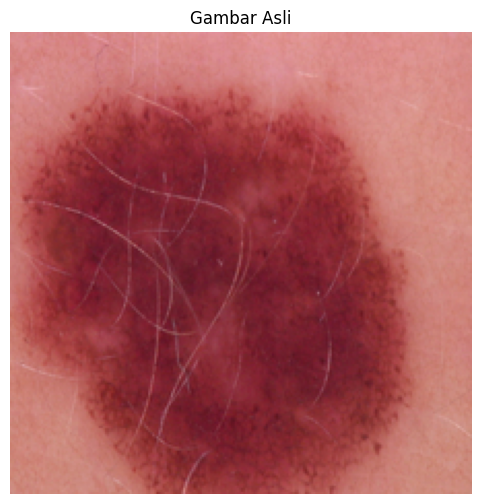

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter

# Ganti dengan path dataset kamu
INPUT_DIR = "/kaggle/input"

# Kumpulkan semua file gambar secara rekursif
ext = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")
image_paths = []
for root, _, files in os.walk(INPUT_DIR):
    for f in files:
        if f.lower().endswith(ext):
            image_paths.append(os.path.join(root, f))

print(f"Total gambar ditemukan: {len(image_paths)}")

# Ambil satu gambar acak
sample_path = random.choice(image_paths)
print("Sample:", sample_path)

original = Image.open(sample_path).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(original)
plt.title("Gambar Asli")
plt.axis("off")
plt.show()

# 2. Gaussian Blur

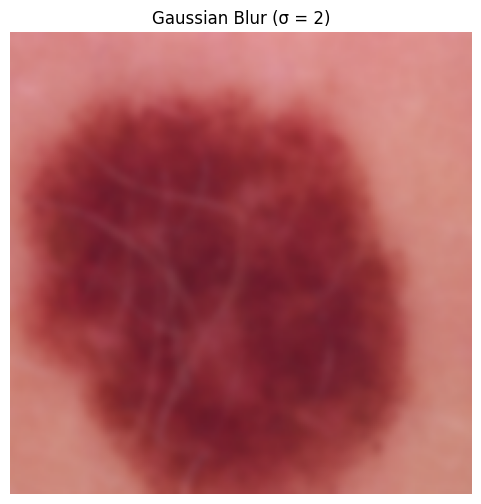

In [2]:
# Pada PIL, parameter radius pada GaussianBlur = standar deviasi (sigma)
gaussian_img = original.filter(ImageFilter.GaussianBlur(radius=2))

plt.figure(figsize=(6, 6))
plt.imshow(gaussian_img)
plt.title("Gaussian Blur (σ = 2)")
plt.axis("off")
plt.show()

# 3. Rotasi

Sudut rotasi: 130.93°


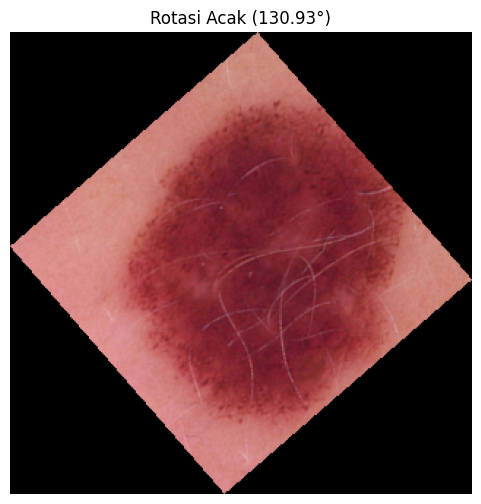

In [3]:
angle = random.uniform(-180, 180)
print(f"Sudut rotasi: {angle:.2f}°")

# expand=True agar gambar tidak terpotong
rotated_img = original.rotate(angle, resample=Image.BICUBIC, expand=True)

plt.figure(figsize=(6, 6))
plt.imshow(rotated_img)
plt.title(f"Rotasi Acak ({angle:.2f}°)")
plt.axis("off")
plt.show()

# 4. Sharpening

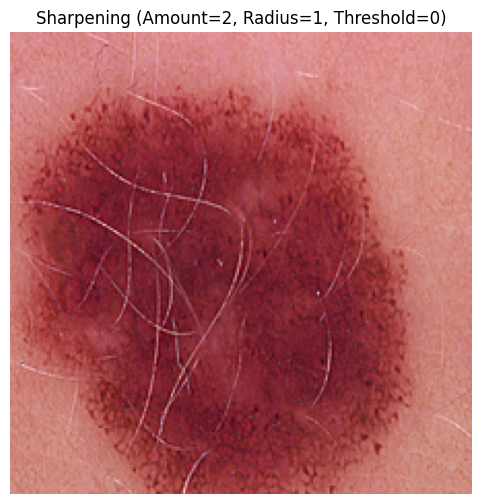

In [4]:
# UnsharpMask di PIL: percent = Amount dalam persen (Amount 2 = 200%)
sharpened_img = original.filter(
    ImageFilter.UnsharpMask(radius=1, percent=200, threshold=0)
)

plt.figure(figsize=(6, 6))
plt.imshow(sharpened_img)
plt.title("Sharpening (Amount=2, Radius=1, Threshold=0)")
plt.axis("off")
plt.show()

# 5. Perbandingan

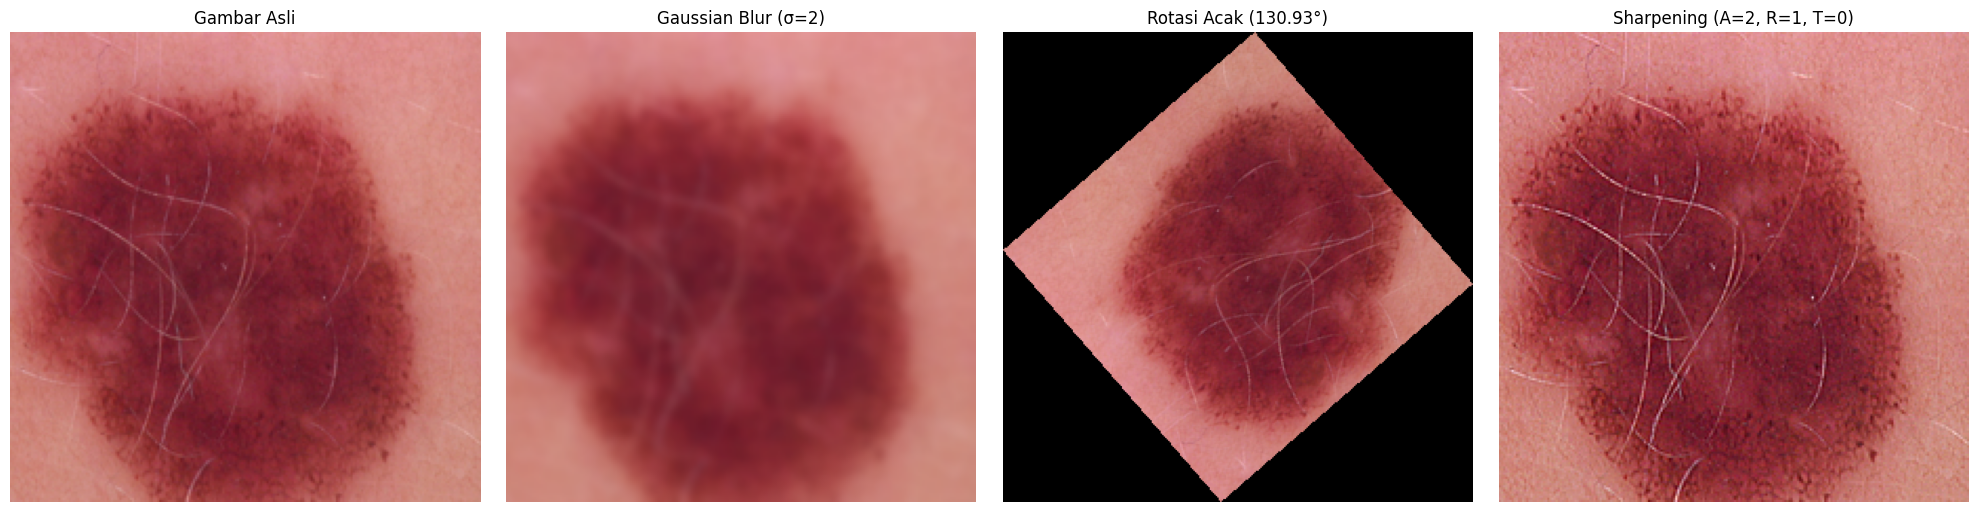

In [5]:
results = [
    ("Gambar Asli", original),
    ("Gaussian Blur (σ=2)", gaussian_img),
    (f"Rotasi Acak ({angle:.2f}°)", rotated_img),
    ("Sharpening (A=2, R=1, T=0)", sharpened_img),
]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (title, img) in zip(axes, results):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 6. Implementasi Model Untuk Grad-CAM menggunakan ResNet50 ImageNet

In [6]:
import torch
import torch.nn.functional as F
from torchvision import models, transforms
import matplotlib.cm as cm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Model pretrained ImageNet (butuh Internet aktif di Kaggle).
# Jika punya model sendiri, ganti bagian ini dengan model hasil training-mu.
weights = models.ResNet50_Weights.IMAGENET1K_V2
model = models.resnet50(weights=weights).to(device).eval()
class_names = weights.meta["categories"]

# Layer konvolusi terakhir sebagai target Grad-CAM
target_layer = model.layer4[-1]

activations, gradients = {}, {}

def forward_hook(module, inp, out):
    activations["value"] = out.detach()
    out.register_hook(lambda grad: gradients.update({"value": grad.detach()}))

hook_handle = target_layer.register_forward_hook(forward_hook)

# Preprocessing
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 153MB/s]


# 7. Hitung Grad-CAM

In [7]:
def compute_gradcam(pil_img, class_idx=None):
    x = preprocess(pil_img).unsqueeze(0).to(device)

    # Forward
    logits = model(x)
    probs = F.softmax(logits, dim=1)
    if class_idx is None:
        class_idx = logits.argmax(dim=1).item()

    # Backward terhadap skor kelas target
    model.zero_grad()
    logits[0, class_idx].backward()

    acts = activations["value"]          # (1, C, H, W)
    grads = gradients["value"]           # (1, C, H, W)

    # Bobot = rata-rata gradien per channel
    weights_c = grads.mean(dim=(2, 3), keepdim=True)

    # Kombinasi linear + ReLU
    cam = F.relu((weights_c * acts).sum(dim=1, keepdim=True))

    # Upsample ke ukuran gambar asli, lalu normalisasi 0-1
    cam = F.interpolate(cam, size=pil_img.size[::-1],
                        mode="bilinear", align_corners=False)
    cam = cam.squeeze().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    return cam, class_idx, probs[0, class_idx].item()

cam, class_idx, conf = compute_gradcam(original)
print(f"Prediksi: {class_names[class_idx]} ({conf*100:.2f}%)")

Prediksi: wool (36.87%)


# 8. Tampilkan Grad-CAM

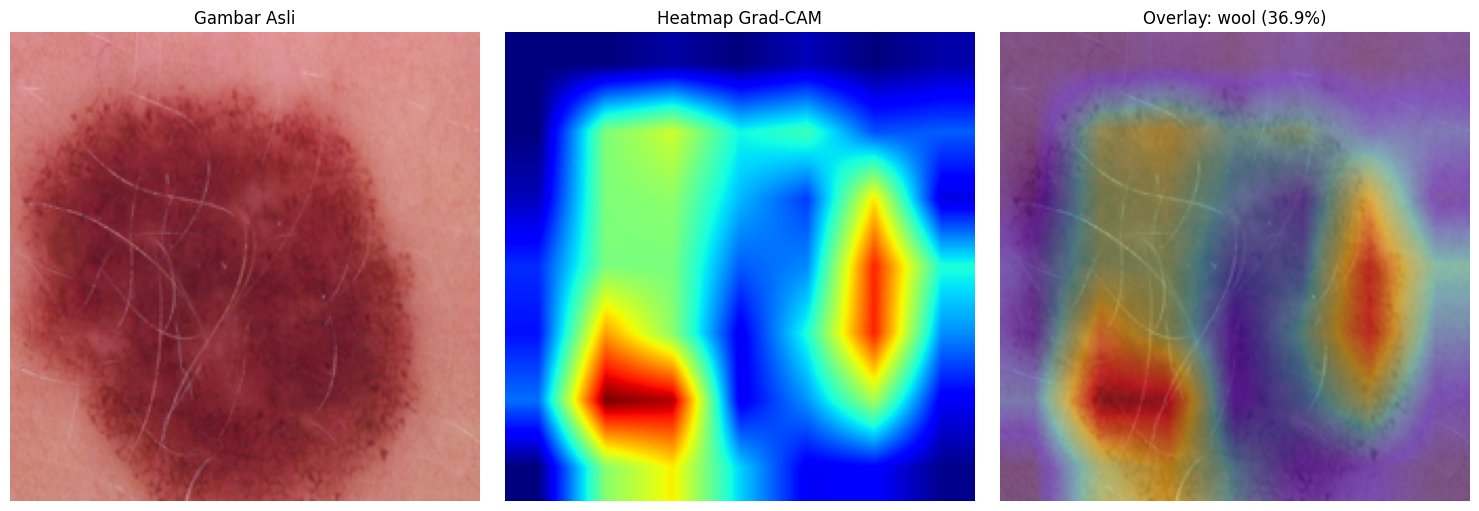

In [8]:
def overlay_cam(pil_img, cam, alpha=0.4):
    heatmap = cm.jet(cam)[..., :3]                 # (H, W, 3) dalam 0-1
    img_np = np.asarray(pil_img).astype(np.float32) / 255.0
    return np.clip((1 - alpha) * img_np + alpha * heatmap, 0, 1)

overlay = overlay_cam(original, cam)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(original)
axes[0].set_title("Gambar Asli")
axes[1].imshow(cam, cmap="jet")
axes[1].set_title("Heatmap Grad-CAM")
axes[2].imshow(overlay)
axes[2].set_title(f"Overlay: {class_names[class_idx]} ({conf*100:.1f}%)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()